# Advanced Algorithms: Network Flows and Matching

> **Prerequisite:** [`dsa/07` Graphs](../dsa/07_graphs.ipynb) (BFS, DFS, shortest paths) and [02 · NP-completeness](02_np_completeness_and_reductions.ipynb) (to appreciate which problems are *easy*).
>
> **Who is this for:** you know graph search and want the most useful "big hammer" in algorithm design: **maximum flow**. A surprising number of problems (assignment, scheduling, matching, image segmentation, tracking, network reliability) become max-flow or min-cost-flow problems and are then solved *exactly* in polynomial time. Standard in CLRS ch. 24–25, Kleinberg & Tardos ch. 7, and in operations-research and computer-vision courses.
>
> **What you will learn:**
> - **Flow networks**, residual graphs and augmenting paths
> - **Ford–Fulkerson** and **Edmonds–Karp** from scratch, with a residual-graph visualisation and a pathological example
> - The **max-flow min-cut theorem**: extract the cut and verify the values match
> - **Bipartite matching** via flow, then **Hopcroft–Karp**; **Hall's theorem** with a computed certificate
> - The **assignment problem**: a from-scratch **Hungarian algorithm** vs `scipy.optimize.linear_sum_assignment`
> - **Min-cost flow** with `networkx` for transport and scheduling
> - **Image segmentation** as a minimum cut on a small synthetic image
> - **Object tracking**: matching detections across frames
> - **Industry mini-case:** assigning support tickets to agents with skills and capacities, compared with a greedy baseline
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb), [`dsa/07`](../dsa/07_graphs.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

Imagine water pipes running from a reservoir to a city. Each pipe can carry only so many litres per second. **Maximum flow** asks: how much water per second can reach the city in total? The answer is limited by the narrowest "bottleneck" set of pipes, and finding that bottleneck is the **minimum cut**. Road traffic from one side of a town to the other works the same way: the total traffic is limited by the bridges you would have to block to cut the town in two.

The same maths solves **matching** problems: assigning students to projects, taxis to passengers, or doctors to night shifts, so that as many as possible get a match, or the total cost is as small as possible. Unlike the NP-hard problems in the previous notebooks, these problems have fast and *exact* algorithms.

**Tiny example.** From your home (S) to school (T) there are two routes: S → A → T, where the roads carry 3 and 2 cars per minute, and S → B → T, where they carry 4 and 5. The first route can carry only 2 (its narrowest road), the second only 4, so at most 2 + 4 = **6** cars per minute can get through. Blocking the roads A → T (2) and S → B (4) cuts you off with total capacity 6: the same number. That is the max-flow min-cut theorem in miniature.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Maximum flow | the most "stuff" you can push from a start to an end through limited pipes | internet traffic, logistics, evacuation planning |
| Minimum cut | the cheapest set of links whose removal separates start from end | network reliability, cutting an image into object vs background |
| Assignment / matching | pair things up so the total cost is lowest (or the most pairs are made) | ride-hailing dispatch, tracking objects in video, DETR's matching loss |

### How this notebook is different from `dsa/07`
[`dsa/07`](../dsa/07_graphs.ipynb) finds paths, spanning trees and components. Here BFS becomes a subroutine: we repeatedly find paths in a *changing* residual graph to push as much flow as possible, and we prove optimality with a matching cut. The applications in the second half (assignment, segmentation, tracking, ticket routing) are things you will meet in real AI systems.

## Table of contents
1. Flow networks and residual graphs
2. Ford–Fulkerson and Edmonds–Karp
3. The max-flow min-cut theorem
4. Bipartite matching, Hopcroft–Karp and Hall's theorem
5. The assignment problem: the Hungarian algorithm
6. Min-cost flow
7. Image segmentation as a minimum cut
8. Object tracking: matching detections across frames
9. Industry mini-case: routing support tickets to agents
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools
from collections import deque, defaultdict, Counter
import networkx as nx
from scipy.optimize import linear_sum_assignment, linprog

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Flow networks and residual graphs

> 💬 **In plain English:** a flow network is a set of one-way pipes with limits; the residual graph shows how much more can be pushed or taken back.

A **flow network** is a directed graph G = (V, E) with a **source** s, a **sink** t and a non-negative **capacity** c(u, v) on each edge. A **flow** f assigns a number to each edge such that:
- **capacity constraint:** 0 ≤ f(u, v) ≤ c(u, v);
- **flow conservation:** for every vertex other than s and t, flow in = flow out.

The **value** |f| is the net flow leaving s. The **maximum-flow problem** asks for a flow of maximum value.

**Residual graph G_f.** Given a flow f, the residual capacity tells us how much more we can push:
- forward: c_f(u, v) = c(u, v) − f(u, v) (unused capacity);
- backward: c_f(v, u) = f(u, v) (we can *cancel* flow already sent, i.e. "undo" an earlier choice).

An **augmenting path** is an s → t path in G_f with all residual capacities > 0. Pushing its **bottleneck** (the smallest residual capacity on it) increases |f|. The backward edges are what make the method correct: without them, a bad early choice could never be repaired.

Worked example (capacities on edges):

```
            10            10
      s ─────────► a ─────────► t          first augmenting path s→a→b→t carries 1
      │           │ ▲          ▲           (bottleneck = the middle edge, capacity 1),
   10 │         1 │ │ (residual: b→a, 1)   which blocks a→b. The residual graph then
      ▼           ▼            │ 10        offers b→a backwards, so s→b→a→t can still
      b ───────────────────────┘           push 1 and undo the bad choice. Max flow = 20.
```

---
## 2. Ford–Fulkerson and Edmonds–Karp

> 💬 **In plain English:** keep finding a route with spare capacity and push as much as it allows; choosing the shortest route keeps this fast.

**Ford–Fulkerson method (1956):** start with f = 0; while an augmenting path exists in G_f, push its bottleneck. With integer capacities each step adds ≥ 1, so it stops after at most |f*| augmentations: **O(E·|f*|)** time, which is pseudo-polynomial (it depends on the capacity values).

**Edmonds–Karp (1972):** always pick the **shortest** augmenting path (fewest edges), found by **BFS**. The BFS distance from s to every vertex never decreases, and each edge can be the bottleneck ("critical") at most O(V) times, so there are O(VE) augmentations of O(E) each: **O(V·E²)**, independent of the capacities.

Faster algorithms exist: Dinic's O(V²E) (and O(E√V) on unit-capacity graphs), push-relabel O(V³), Orlin's O(VE) (2013), and in 2022 an **almost-linear-time** algorithm, m^(1+o(1)) (Chen, Kyng, Liu, Peng, Probst Gutenberg & Sachdeva). Edmonds–Karp remains the one to understand first.

In [2]:
class FlowNetwork:
    """Residual-capacity representation. cap[u][v] is the *residual* capacity of u→v."""
    def __init__(self):
        self.cap = defaultdict(lambda: defaultdict(int))
        self.original = {}                                   # (u, v) -> original capacity

    def add_edge(self, u, v, c):
        self.cap[u][v] += c
        self.cap[v][u] += 0                                  # make sure the reverse edge exists
        self.original[(u, v)] = self.original.get((u, v), 0) + c

    def flow_on(self, u, v):
        """Flow on an original edge = original capacity − residual capacity (clipped at 0 for 2-cycles)."""
        return max(0, self.original[(u, v)] - self.cap[u][v])

def bfs_path(net, s, t):
    """Shortest augmenting path (fewest edges) as a parent map, or None."""
    parent = {s: None}
    q = deque([s])
    while q:
        u = q.popleft()
        for v, c in net.cap[u].items():
            if c > 0 and v not in parent:
                parent[v] = u
                if v == t:
                    return parent
                q.append(v)
    return None

def dfs_path(net, s, t):
    """Any augmenting path, found by depth-first search (plain Ford–Fulkerson)."""
    parent, stack = {s: None}, [s]
    while stack:
        u = stack.pop()
        if u == t:
            return parent
        for v, c in net.cap[u].items():
            if c > 0 and v not in parent:
                parent[v] = u
                stack.append(v)
    return None

def max_flow(net, s, t, find_path=bfs_path):
    """Ford–Fulkerson with a pluggable path finder (BFS = Edmonds–Karp). Returns (value, #augmentations)."""
    value, augmentations = 0, 0
    while True:
        parent = find_path(net, s, t)
        if parent is None:
            return value, augmentations
        path, v = [], t                                      # walk back from t to s
        while parent[v] is not None:
            path.append((parent[v], v)); v = parent[v]
        bottleneck = min(net.cap[u][v] for u, v in path)
        for u, v in path:
            net.cap[u][v] -= bottleneck                      # use forward residual capacity
            net.cap[v][u] += bottleneck                      # and allow it to be undone later
        value += bottleneck
        augmentations += 1

# The CLRS-style example network
edges = [("s", "v1", 16), ("s", "v2", 13), ("v1", "v3", 12), ("v2", "v1", 4), ("v2", "v4", 14),
         ("v3", "v2", 9), ("v3", "t", 20), ("v4", "v3", 7), ("v4", "t", 4)]
net = FlowNetwork()
for u, v, c in edges:
    net.add_edge(u, v, c)
value, aug = max_flow(net, "s", "t")
G = nx.DiGraph(); G.add_weighted_edges_from(edges, weight="capacity")
print(f"Edmonds-Karp max flow = {value} using {aug} augmenting paths; networkx says {nx.maximum_flow_value(G, 's', 't')}")
for u, v, c in edges:
    print(f"  {u:>2} → {v:<2}: flow {net.flow_on(u, v):2d} / {c}")

Edmonds-Karp max flow = 23 using 3 augmenting paths; networkx says 23
   s → v1: flow 12 / 16
   s → v2: flow 11 / 13
  v1 → v3: flow 12 / 12
  v2 → v1: flow  0 / 4
  v2 → v4: flow 11 / 14
  v3 → v2: flow  0 / 9
  v3 → t : flow 19 / 20
  v4 → v3: flow  7 / 7
  v4 → t : flow  4 / 4


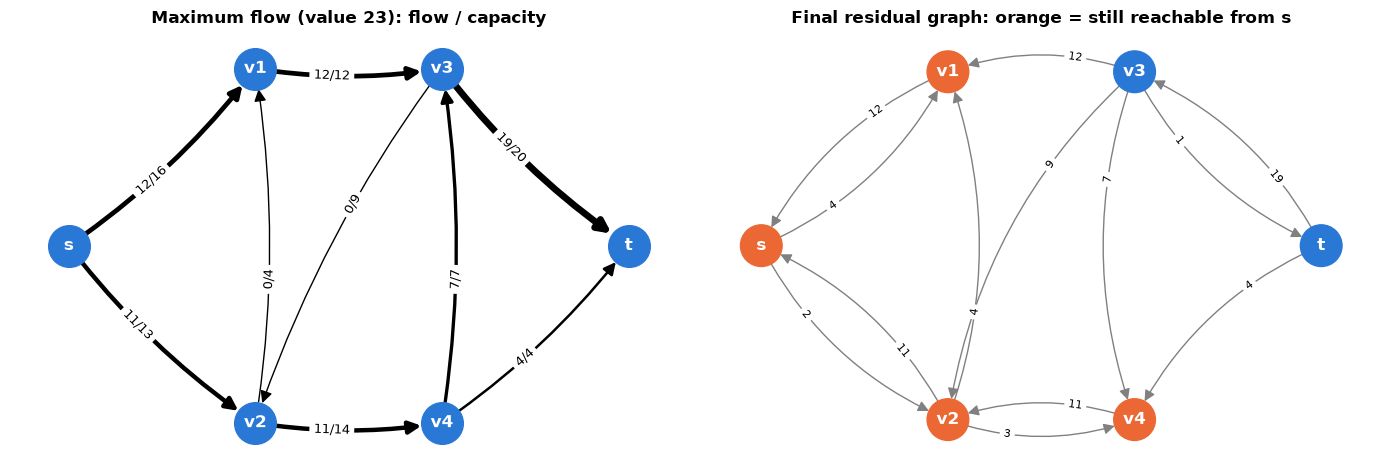

In [3]:
pos = {"s": (0, 1), "v1": (1, 2), "v2": (1, 0), "v3": (2, 2), "v4": (2, 0), "t": (3, 1)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# Left: flow / capacity on every original edge
ax = axes[0]
nx.draw_networkx_nodes(G, pos, node_color=PALETTE[0], node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, font_color="white", font_weight="bold", ax=ax)
widths = [1 + 4 * net.flow_on(u, v) / 20 for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=widths, arrowsize=18, node_size=900, connectionstyle="arc3,rad=0.08", ax=ax)
nx.draw_networkx_edge_labels(G, pos, {(u, v): f"{net.flow_on(u, v)}/{d['capacity']}" for u, v, d in G.edges(data=True)},
                             label_pos=0.4, font_size=9, ax=ax, connectionstyle="arc3,rad=0.08")
ax.set_title(f"Maximum flow (value {value}): flow / capacity"); ax.axis("off")
# Right: the final residual graph (only edges with positive residual capacity)
R = nx.DiGraph()
for u in list(net.cap):
    for v, c in net.cap[u].items():
        if c > 0: R.add_edge(u, v, r=c)
ax = axes[1]
reach = nx.descendants(R, "s") | {"s"}
nx.draw_networkx_nodes(R, pos, node_color=[PALETTE[1] if n in reach else PALETTE[0] for n in R], node_size=900, ax=ax)
nx.draw_networkx_labels(R, pos, font_color="white", font_weight="bold", ax=ax)
nx.draw_networkx_edges(R, pos, arrowsize=16, node_size=900, connectionstyle="arc3,rad=0.18", ax=ax, edge_color="gray")
nx.draw_networkx_edge_labels(R, pos, {(u, v): d["r"] for u, v, d in R.edges(data=True)}, label_pos=0.3,
                             font_size=8, ax=ax, connectionstyle="arc3,rad=0.18")
ax.set_title("Final residual graph: orange = still reachable from s"); ax.axis("off")
plt.tight_layout(); plt.show()

**What just happened?** Edmonds–Karp found the maximum flow, 23, with a handful of BFS augmentations, matching networkx. In the left plot, thicker edges carry more flow, and every vertex except s and t has flow in = flow out. In the residual graph on the right, **no path from s to t remains**: the orange vertices (reachable from s) are cut off from the rest. That set is exactly the minimum cut of section 3.

**Why the choice of path matters.** Below, the middle edge a→b has capacity 1 and the other four edges have capacity C. An unlucky Ford–Fulkerson that keeps choosing paths through the middle edge alternates s→a→b→t and s→b→a→t (the second one uses the *backward* residual edge b→a), gaining only 1 each time: 2C augmentations. BFS finds the two length-2 paths immediately.

In [4]:
def bad_network(C):
    net = FlowNetwork()
    for u, v, c in [("s", "a", C), ("s", "b", C), ("a", "t", C), ("b", "t", C), ("a", "b", 1)]:
        net.add_edge(u, v, c)
    return net

def adversarial_path(net, s, t):
    """An unlucky Ford–Fulkerson: whenever possible, choose a path through the middle edge."""
    for path in (["s", "a", "b", "t"], ["s", "b", "a", "t"]):
        if all(net.cap[u][v] > 0 for u, v in zip(path, path[1:])):
            return {path[i + 1]: path[i] for i in range(len(path) - 1)} | {s: None}
    return dfs_path(net, s, t)

rows = []
for C in [10, 100, 1000]:
    v1, a1 = max_flow(bad_network(C), "s", "t", find_path=adversarial_path)
    v2, a2 = max_flow(bad_network(C), "s", "t", find_path=bfs_path)
    rows.append({"C": C, "max flow": v2, "Ford-Fulkerson (unlucky paths) augmentations": a1, "Edmonds-Karp augmentations": a2})
    assert v1 == v2 == 2 * C
print(pd.DataFrame(rows).to_string(index=False))

# Randomized differential test against networkx
rng = random.Random(0)
for trial in range(150):
    n = rng.randint(2, 12)
    G_r = nx.gnp_random_graph(n, rng.uniform(0.2, 0.7), seed=trial, directed=True)
    netr = FlowNetwork()
    for u, v in G_r.edges():
        c = rng.randint(1, 20); G_r[u][v]["capacity"] = c; netr.add_edge(u, v, c)
    net_dfs = FlowNetwork()
    for u, v in G_r.edges():
        net_dfs.add_edge(u, v, G_r[u][v]["capacity"])
    ours, _ = max_flow(netr, 0, n - 1)
    ours_dfs, _ = max_flow(net_dfs, 0, n - 1, find_path=dfs_path)
    assert ours == ours_dfs == nx.maximum_flow_value(G_r, 0, n - 1)
print("Edmonds-Karp and DFS Ford-Fulkerson match networkx on 150 random directed graphs")

   C  max flow  Ford-Fulkerson (unlucky paths) augmentations  Edmonds-Karp augmentations
  10        20                                            20                           2
 100       200                                           200                           2
1000      2000                                          2000                           2


Edmonds-Karp and DFS Ford-Fulkerson match networkx on 150 random directed graphs


**What just happened?** With unlucky path choices, plain Ford–Fulkerson needs **2C** augmentations (20, 200, 2000), so its running time depends on the size of the numbers. Edmonds–Karp needs 2, whatever C is. (With *irrational* capacities, Ford–Fulkerson with bad choices may not even terminate.) Both our path finders (BFS and DFS) also matched networkx on 150 random graphs.

| Algorithm | Path choice | Time | Notes |
|---|---|---|---|
| Ford–Fulkerson | any augmenting path | O(E·\|f*\|) | integer capacities; can be slow |
| Edmonds–Karp | shortest (BFS) | O(V E²) | simple, strongly polynomial |
| Dinic | blocking flows in BFS level graph | O(V² E); O(E√V) for unit capacities | used in contests and libraries |
| Push–relabel | local "preflow" pushes | O(V³) (FIFO), O(V² √E) (highest label) | fast in practice |
| Chen et al. 2022 | interior point + dynamic data structures | m^(1+o(1)) | theoretical breakthrough |

---
## 3. The max-flow min-cut theorem

> 💬 **In plain English:** the most you can push equals the cheapest set of pipes you would have to cut, and the algorithm hands you that cut.

An **s-t cut** (S, T) splits V into S ∋ s and T = V ∖ S ∋ t. Its **capacity** is the total capacity of edges going *from S to T* (edges from T back to S do not count). Every flow must cross every cut, so |f| ≤ c(S, T) for any flow and any cut.

**Max-flow min-cut theorem (Ford & Fulkerson 1956; Elias, Feinstein & Shannon 1956).** The following are equivalent:
1. f is a maximum flow;
2. the residual graph G_f has no augmenting path;
3. |f| = c(S, T) for some cut (S, T).

**Proof idea of 2 ⇒ 3:** let S be the vertices reachable from s in G_f. Then t ∉ S. Every edge from S to T must be saturated (otherwise its endpoint would be reachable), and every edge from T to S must carry 0 flow (otherwise its backward residual edge would make it reachable). So the net flow across the cut equals its capacity. So **after Edmonds–Karp, BFS from s in the residual graph gives a minimum cut for free.**

In [5]:
def min_cut_from_residual(net, s):
    """S = vertices reachable from s using positive residual capacity."""
    seen, q = {s}, deque([s])
    while q:
        u = q.popleft()
        for v, c in net.cap[u].items():
            if c > 0 and v not in seen:
                seen.add(v); q.append(v)
    return seen

S = min_cut_from_residual(net, "s")
cut_edges = [(u, v, c) for u, v, c in edges if u in S and v not in S]
print("S side:", sorted(S), "| T side:", sorted(set(pos) - S))
print("cut edges:", [(u, v) for u, v, _ in cut_edges], "capacity =", sum(c for *_, c in cut_edges), "= max flow", value)

# Check the theorem on random graphs, and that our cut is a true minimum (networkx minimum_cut)
rng = random.Random(1)
for trial in range(100):
    n = rng.randint(3, 12)
    G_r = nx.gnp_random_graph(n, 0.4, seed=100 + trial, directed=True)
    netr = FlowNetwork()
    for u, v in G_r.edges():
        c = rng.randint(1, 15); G_r[u][v]["capacity"] = c; netr.add_edge(u, v, c)
    f_val, _ = max_flow(netr, 0, n - 1)
    S_r = min_cut_from_residual(netr, 0)
    cut_cap = sum(G_r[u][v]["capacity"] for u, v in G_r.edges() if u in S_r and v not in S_r)
    assert n - 1 not in S_r and cut_cap == f_val == nx.minimum_cut(G_r, 0, n - 1)[0]
print("max flow = capacity of the residual-reachability cut = networkx min cut, on 100 random graphs")

S side: ['s', 'v1', 'v2', 'v4'] | T side: ['t', 'v3']
cut edges: [('v1', 'v3'), ('v4', 'v3'), ('v4', 't')] capacity = 23 = max flow 23
max flow = capacity of the residual-reachability cut = networkx min cut, on 100 random graphs


**What just happened?** The vertices still reachable from s after the algorithm stops form the S side of the cut. Its outgoing edges are all saturated, and their capacities add up to exactly 23, the maximum flow. The 100 random graphs confirm the theorem numerically. The cut is a **certificate of optimality**: anyone can check that no flow can exceed it.

> 🎓 **Exam / interview tip:** max-flow min-cut is a special case of **LP duality** (the next notebook, 05, covers LP): the max-flow LP and the min-cut LP are duals, and their optimal values coincide.

---
## 4. Bipartite matching, Hopcroft–Karp and Hall's theorem

> 💬 **In plain English:** pairing people with jobs is a flow problem, and a quick search either finds a full pairing or proves why none exists.

A graph is **bipartite** if its vertices split into two sides L and R with edges only between the sides (workers and jobs, students and projects). A **matching** is a set of edges with no shared endpoints; we want a **maximum matching**.

**Reduction to max-flow.** Add a source s → every vertex of L (capacity 1), every vertex of R → sink t (capacity 1), and direct the L–R edges from L to R (capacity 1). An integer max flow is a maximum matching: the **integrality theorem** says that with integer capacities, Ford–Fulkerson finds an integer max flow. Time O(VE), since |f*| ≤ V.

**Hopcroft–Karp (1973):** in each phase, BFS from all free left vertices to build layers, then find a **maximal set of vertex-disjoint shortest augmenting paths** with DFS. Only O(√V) phases are needed, so the time is **O(E√V)**.

**Hall's marriage theorem (1935).** A bipartite graph has a matching saturating all of L **iff** for every subset A ⊆ L, |N(A)| ≥ |A|, where N(A) is the set of neighbours of A. ("Any k applicants together must be qualified for at least k jobs.") When the maximum matching is smaller than |L|, the set of left vertices reachable from a free left vertex by **alternating paths** is a violating set A with |N(A)| < |A|: a short certificate that no perfect matching exists.

In [6]:
def hopcroft_karp(L, adj):
    """Maximum bipartite matching. adj[u] = list of right vertices for left vertex u. O(E sqrt V)."""
    match_L = {u: None for u in L}
    match_R = {}
    INF = float("inf")

    def bfs():
        dist, q, found = {}, deque(), False
        for u in L:
            if match_L[u] is None:
                dist[u] = 0; q.append(u)                    # free left vertices start the layers
            else:
                dist[u] = INF
        while q:
            u = q.popleft()
            for v in adj[u]:
                w = match_R.get(v)
                if w is None:
                    found = True                             # reached a free right vertex
                elif dist[w] == INF:
                    dist[w] = dist[u] + 1; q.append(w)
        return found, dist

    def dfs(u, dist):
        for v in adj[u]:
            w = match_R.get(v)
            if w is None or (dist[w] == dist[u] + 1 and dfs(w, dist)):
                match_L[u], match_R[v] = v, u                 # flip the path's edges
                return True
        dist[u] = INF                                        # dead end: never revisit in this phase
        return False

    phases = 0
    while True:
        found, dist = bfs()
        if not found:
            break
        phases += 1
        for u in L:
            if match_L[u] is None:
                dfs(u, dist)
    return {u: v for u, v in match_L.items() if v is not None}, phases

def matching_by_flow(L, adj):
    net = FlowNetwork()
    for u in L:
        net.add_edge("S", ("L", u), 1)
        for v in adj[u]:
            net.add_edge(("L", u), ("R", v), 1)
    for v in {v for u in L for v in adj[u]}:
        net.add_edge(("R", v), "T", 1)
    value, _ = max_flow(net, "S", "T")
    return value

def hall_violator(L, adj, matching):
    """If the matching leaves a left vertex free, return A ⊆ L with |N(A)| < |A| (alternating-path search)."""
    free = [u for u in L if u not in matching]
    if not free:
        return None
    match_R = {v: u for u, v in matching.items()}
    A, q = {free[0]}, deque([free[0]])
    while q:
        u = q.popleft()
        for v in adj[u]:                                     # non-matching edge to the right side...
            w = match_R.get(v)                               # ...then the matching edge back to the left
            if w is not None and w not in A:
                A.add(w); q.append(w)
    return A

rng = random.Random(2)
for trial in range(200):
    nL, nR = rng.randint(1, 9), rng.randint(1, 9)
    L = list(range(nL))
    adj = {u: [v for v in range(nR) if rng.random() < 0.3] for u in L}
    M, _ = hopcroft_karp(L, adj)
    B = nx.Graph(); B.add_nodes_from(("L", u) for u in L); B.add_nodes_from(("R", v) for v in range(nR))
    B.add_edges_from((("L", u), ("R", v)) for u in L for v in adj[u])
    nx_size = len(nx.bipartite.maximum_matching(B, top_nodes=[("L", u) for u in L])) // 2
    assert len(M) == matching_by_flow(L, adj) == nx_size
    assert len(set(M.values())) == len(M) and all(v in adj[u] for u, v in M.items())
    A = hall_violator(L, adj, M)
    if A is not None:
        N = {v for u in A for v in adj[u]}
        assert len(N) < len(A)                               # the certificate really violates Hall's condition
    else:
        assert len(M) == nL
    # Hall's theorem by brute force over all subsets (small sides only)
    hall_ok = all(len({v for u in sub for v in adj[u]}) >= len(sub)
                  for k in range(1, nL + 1) for sub in itertools.combinations(L, k))
    assert hall_ok == (len(M) == nL)
print("Hopcroft-Karp = max-flow matching = networkx on 200 random bipartite graphs; Hall certificates verified")

# Speed: Hopcroft-Karp on a larger random bipartite graph
nL = nR = 3000
adj = {u: random.Random(u).sample(range(nR), 4) for u in range(nL)}
t0 = time.perf_counter(); M, phases = hopcroft_karp(list(range(nL)), adj); dt = time.perf_counter() - t0
print(f"n = {nL}+{nR}, E = {4 * nL}: matching size {len(M)} found in {phases} phases ({dt:.2f} s); sqrt(V) ≈ {math.sqrt(2 * nL):.0f}")

Hopcroft-Karp = max-flow matching = networkx on 200 random bipartite graphs; Hall certificates verified


n = 3000+3000, E = 12000: matching size 2949 found in 5 phases (0.23 s); sqrt(V) ≈ 77


**What just happened?** Three independent methods (Hopcroft–Karp, our max-flow reduction and networkx) found matchings of the same size on 200 random bipartite graphs. Whenever the matching did not cover all of L, the alternating-path search produced a set A of left vertices with fewer neighbours than members, and brute force over all subsets confirmed Hall's condition holds exactly when a perfect left matching exists. On a graph with 6,000 vertices Hopcroft–Karp needed only a handful of phases, far fewer than √V.

> 🎓 **Exam / interview tip:** **König's theorem**: in a *bipartite* graph, the maximum matching size equals the minimum vertex cover size. So vertex cover, NP-hard in general ([03](03_approximation_and_parameterized_algorithms.ipynb)), is solvable exactly by max-flow on bipartite graphs (practice problem 5).

---
## 5. The assignment problem: the Hungarian algorithm

> 💬 **In plain English:** give n workers n jobs at the lowest total cost, exactly, in about n³ steps instead of n! tries.

**Assignment problem:** n workers, n jobs, cost[i][j] for worker i doing job j. Find a perfect matching (a permutation) of **minimum total cost**. Brute force tries n! permutations. The **Hungarian algorithm** (Kuhn 1955, based on Kőnig and Egerváry; Munkres 1957) solves it in **O(n³)**.

**Idea.** Keep "prices" (dual potentials) u_i for rows and v_j for columns with u_i + v_j ≤ cost[i][j] for all i, j. An edge is **tight** if u_i + v_j = cost[i][j]. Grow a matching using only tight edges (augmenting paths, as in section 4); when stuck, raise the potentials by the smallest slack δ so that a new tight edge appears. When the matching is perfect, its cost equals Σu_i + Σv_j, a lower bound on every assignment (LP duality), so it is optimal.

Worked example by hand with the classic tableau method (reduce rows and columns, then cover zeros):
```
cost        − row minima (1,0,2)    − column minima (1,0,0)    zeros: rows 0 and 1 both only
 4 1 3          3 0 2                   2 0 2                    have a zero in column 1, so
 2 0 5    →     2 0 5             →     1 0 5                    only 2 independent zeros
 3 2 2          1 0 0                   0 0 0                    (cover: column 1 + row 2)

smallest uncovered value = 1: subtract it from uncovered cells, add it where the lines cross:
 1 0 1      independent zeros: row 0 → col 1, row 1 → col 0, row 2 → col 2
 0 0 4      original costs:    1     +      2     +      2      = 5  (optimal)
 0 1 0
```

In [7]:
def hungarian(cost):
    """Minimum-cost assignment, O(n^2 m) with potentials (n rows <= m columns).
    Returns (total cost, assignment list: row i -> column)."""
    n, m = len(cost), len(cost[0])
    INF = float("inf")
    u = [0.0] * (n + 1); v = [0.0] * (m + 1)                 # dual potentials (1-indexed; index 0 is a dummy)
    p = [0] * (m + 1)                                        # p[j] = row matched to column j (0 = none)
    way = [0] * (m + 1)                                      # for reconstructing the augmenting path
    for i in range(1, n + 1):
        p[0] = i
        j0 = 0
        minv = [INF] * (m + 1)                               # smallest reduced cost to reach each column
        used = [False] * (m + 1)
        while True:                                          # Dijkstra-like search for an augmenting path
            used[j0] = True
            i0, delta, j1 = p[j0], INF, 0
            for j in range(1, m + 1):
                if not used[j]:
                    cur = cost[i0 - 1][j - 1] - u[i0] - v[j]  # reduced cost (slack) of edge (i0, j)
                    if cur < minv[j]:
                        minv[j], way[j] = cur, j0
                    if minv[j] < delta:
                        delta, j1 = minv[j], j
            for j in range(m + 1):                           # shift potentials by delta: a new tight edge appears
                if used[j]:
                    u[p[j]] += delta; v[j] -= delta
                else:
                    minv[j] -= delta
            j0 = j1
            if p[j0] == 0:                                   # reached a free column: augment
                break
        while True:                                          # flip the augmenting path
            j1 = way[j0]; p[j0] = p[j1]; j0 = j1
            if j0 == 0:
                break
    assign = [0] * n
    for j in range(1, m + 1):
        if p[j]:
            assign[p[j] - 1] = j - 1
    return sum(cost[i][assign[i]] for i in range(n)), assign

C = [[4, 1, 3], [2, 0, 5], [3, 2, 2]]
total, assign = hungarian(C)
print("hand example: total =", total, "assignment row→col:", assign)
assert total == 5

rng_np = np.random.default_rng(0)
for trial in range(200):                                     # vs brute force (small n) and SciPy
    n = int(rng_np.integers(1, 8))
    M = rng_np.integers(0, 50, size=(n, n))
    ours, a = hungarian(M.tolist())
    r, c = linear_sum_assignment(M)
    brute = min(sum(M[i, perm[i]] for i in range(n)) for perm in itertools.permutations(range(n)))
    assert ours == M[r, c].sum() == brute and sorted(a) == list(range(n))
for trial in range(50):                                      # rectangular (more jobs than workers), real costs
    M = rng_np.random((int(rng_np.integers(1, 9)), 9))
    ours, _ = hungarian(M.tolist()); r, c = linear_sum_assignment(M)
    assert abs(ours - M[r, c].sum()) < 1e-9
print("Hungarian = brute force = scipy on 200 square instances; = scipy on 50 rectangular ones")

rows = []
for n in [25, 50, 100, 200]:
    M = rng_np.random((n, n))
    t0 = time.perf_counter(); ours, _ = hungarian(M.tolist()); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); r, c = linear_sum_assignment(M); t_sp = time.perf_counter() - t0
    assert abs(ours - M[r, c].sum()) < 1e-9
    rows.append({"n": n, "ours (pure Python) s": round(t_ours, 4), "scipy (C++) s": round(t_sp, 5),
                 "n! permutations": f"≈ 10^{math.lgamma(n + 1) / math.log(10):.0f}"})
print(pd.DataFrame(rows).to_string(index=False))

hand example: total = 5 assignment row→col: [1, 0, 2]


Hungarian = brute force = scipy on 200 square instances; = scipy on 50 rectangular ones
  n  ours (pure Python) s  scipy (C++) s n! permutations
 25                0.0016        0.00006         ≈ 10^25
 50                0.0067        0.00017         ≈ 10^64
100                0.0297        0.00061        ≈ 10^158
200                0.1539        0.00260        ≈ 10^375


**What just happened?** On the hand example the Hungarian algorithm found total cost 5 (row 0 → col 1, row 1 → col 0, row 2 → col 2: 1 + 2 + 2). It agreed with brute force over all n! permutations and with SciPy on hundreds of random instances, including rectangular ones. Our pure-Python version's worst case is O(n³); on random matrices it usually finds augmenting paths quickly, so the measured growth is gentler than ×8 per doubling of n. SciPy's C++ implementation is still one to two orders of magnitude faster. Use SciPy in practice, but now you know what it does. Brute force would be hopeless: 200! has 375 digits.

---
## 6. Min-cost flow

> 💬 **In plain English:** ship goods from suppliers to customers at the lowest cost while respecting route limits.

**Min-cost flow** generalises both max-flow and assignment: each edge has a capacity **and** a cost per unit of flow; nodes have **supplies** (positive) or **demands** (negative); find the cheapest flow that meets all demands. It can be solved in polynomial time (e.g. successive shortest paths, cycle cancelling, or the network simplex used by networkx). With integer data there is always an integer optimal solution.

Applications: transport and distribution, staff scheduling, supply chains, routing with tolls, and assignment with capacities (section 9).

**Example: transport.** Three factories supply 60, 50 and 40 units; four warehouses need 30, 45, 35 and 40. Each route has a per-unit cost and a capacity.

In [8]:
factories = {"F1": 60, "F2": 50, "F3": 40}
warehouses = {"W1": 30, "W2": 45, "W3": 35, "W4": 40}
unit_cost = {("F1", "W1"): 4, ("F1", "W2"): 6, ("F1", "W3"): 9, ("F1", "W4"): 5,
             ("F2", "W1"): 5, ("F2", "W2"): 3, ("F2", "W3"): 7, ("F2", "W4"): 8,
             ("F3", "W1"): 6, ("F3", "W2"): 4, ("F3", "W3"): 2, ("F3", "W4"): 7}
route_cap = 35                                              # no truck route can carry more than 35 units

T = nx.DiGraph()
for f, s_ in factories.items():
    T.add_node(f, demand=-s_)                                # networkx: negative demand = supply
for w, d in warehouses.items():
    T.add_node(w, demand=d)
for (f, w), c in unit_cost.items():
    T.add_edge(f, w, weight=c, capacity=route_cap)
flow = nx.min_cost_flow(T)
total = nx.cost_of_flow(T, flow)
plan = pd.DataFrame({w: {f: flow[f].get(w, 0) for f in factories} for w in warehouses})
print(plan); print("total transport cost =", total)

# Check with a linear program: min Σ c x  s.t. supplies, demands, 0 <= x <= cap
keys = list(unit_cost)
A_eq, b_eq = [], []
for f, s_ in factories.items():
    A_eq.append([1 if k[0] == f else 0 for k in keys]); b_eq.append(s_)
for w, d in warehouses.items():
    A_eq.append([1 if k[1] == w else 0 for k in keys]); b_eq.append(d)
lp = linprog([unit_cost[k] for k in keys], A_eq=A_eq, b_eq=b_eq, bounds=[(0, route_cap)] * len(keys), method="highs")
print("LP optimum =", round(lp.fun, 6))
assert abs(lp.fun - total) < 1e-6

    W1  W2  W3  W4
F1  20   5   0  35
F2  10  35   0   5
F3   0   5  35   0
total transport cost = 570
LP optimum = 570.0


**What just happened?** networkx's network simplex found an integer shipping plan meeting every supply and demand while respecting the 35-unit route limit. The same problem written as a linear program (the next notebook, 05, covers LP) gives the same optimal cost, as it must: min-cost flow is an LP whose constraint matrix is **totally unimodular**, which is why its optimal vertices are integers. Look at the plan: cheap routes (F3 → W3 at cost 2, F2 → W2 at cost 3) are used up to their capacity first.

---
## 7. Image segmentation as a minimum cut

> 💬 **In plain English:** separating an object from the background becomes cutting a pixel network at its cheapest place.

**Goal:** label every pixel as foreground (object) or background in a noisy image. Two wishes compete:
- **data term:** a pixel that looks bright should be foreground; a dark one, background;
- **smoothness term:** neighbouring pixels should usually get the same label.

The energy E(labels) = Σ_p D_p(label_p) + λ · #(neighbouring pairs with different labels) can be minimised **exactly** with one minimum cut (Greig, Porteous & Seheult 1989; Boykov & Jolly 2001, the "graph cuts" behind GrabCut):
- source s = "foreground", sink t = "background";
- edge s → p with capacity D_p(background) (you pay it if p ends up on the background side);
- edge p → t with capacity D_p(foreground);
- edges p ↔ q between 4-neighbours with capacity λ (paid when they are separated).

Every s-t cut corresponds to a labelling, and its capacity equals the energy. So the minimum cut is the best labelling. (Exact for two labels with this kind of "submodular" smoothness; for more labels, α-expansion repeats binary cuts with approximation guarantees.)

20x20 image: min cut = 1881 (networkx 1881), 478 augmenting paths, 0.42 s


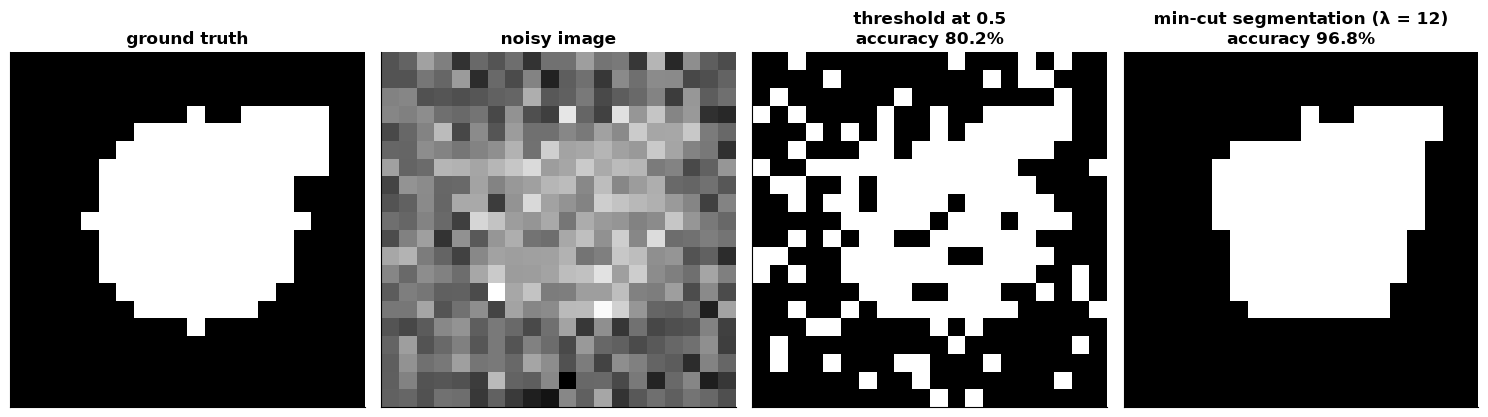

In [9]:
H = W_img = 20
yy, xx = np.mgrid[:H, :W_img]
truth = ((yy - 9) ** 2 + (xx - 10) ** 2 <= 36) | ((yy >= 3) & (yy <= 6) & (xx >= 13) & (xx <= 17))   # disk + bar
rng_np = np.random.default_rng(4)
img = np.where(truth, 0.65, 0.35) + rng_np.normal(0, 0.18, size=truth.shape)                  # noisy image

SCALE, lam = 100, 12                                      # integer capacities keep the arithmetic exact
D_fg = np.round(SCALE * (img - 0.65) ** 2).astype(int)    # cost of calling a pixel foreground
D_bg = np.round(SCALE * (img - 0.35) ** 2).astype(int)    # cost of calling it background

seg = FlowNetwork(); Gs = nx.DiGraph()
def add(u, v, c):
    seg.add_edge(u, v, c)
    Gs.add_edge(u, v, capacity=Gs.get_edge_data(u, v, {"capacity": 0})["capacity"] + c)
for y in range(H):
    for x in range(W_img):
        p = (y, x)
        add("s", p, int(D_bg[y, x])); add(p, "t", int(D_fg[y, x]))
        for q in [(y + 1, x), (y, x + 1)]:                # 4-neighbourhood, both directions
            if q[0] < H and q[1] < W_img:
                add(p, q, lam); add(q, p, lam)

t0 = time.perf_counter()
cut_value, n_aug = max_flow(seg, "s", "t")
t_seg = time.perf_counter() - t0
fg = min_cut_from_residual(seg, "s")
labels = np.array([[(y, x) in fg for x in range(W_img)] for y in range(H)])
nx_value = nx.minimum_cut(Gs, "s", "t")[0]
print(f"{H}x{W_img} image: min cut = {cut_value} (networkx {nx_value}), {n_aug} augmenting paths, {t_seg:.2f} s")
assert cut_value == nx_value

threshold = img > 0.5
acc_thr, acc_cut = (threshold == truth).mean(), (labels == truth).mean()
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, im, title in zip(axes, [truth, img, threshold, labels],
                         ["ground truth", "noisy image", f"threshold at 0.5\naccuracy {acc_thr:.1%}",
                          f"min-cut segmentation (λ = {lam})\naccuracy {acc_cut:.1%}"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()
assert acc_cut > acc_thr

**What just happened?** Thresholding each pixel on its own leaves salt-and-pepper errors, because the noise is large. The min-cut labelling balances each pixel's evidence against agreement with its neighbours and recovers clean shapes, with clearly higher accuracy (the exact numbers are in the panel titles). The cut value from our Edmonds–Karp matched networkx exactly, so this labelling is the **global** minimum of the energy, not a local optimum. λ is the knob: λ = 0 reproduces thresholding, and a very large λ makes everything one label.

Modern deep segmentation networks ([`06_Computer_Vision/04_image_segmentation`](../../06_Computer_Vision/04_image_segmentation.ipynb)) learn the data term, and CRF or graph-cut post-processing has long been used to sharpen their boundaries.

---
## 8. Object tracking: matching detections across frames

> 💬 **In plain English:** to follow objects through a video, match each new detection to the closest existing track.

A multi-object tracker (SORT, DeepSORT, ByteTrack) runs a detector on each video frame and must decide which detection in frame t+1 is the same object as each track from frame t. That is an **assignment problem**: cost = distance between the predicted and detected positions (or 1 − IoU of the boxes, or an appearance-embedding distance). Solve it with the Hungarian algorithm, then apply a **gate**: matches costlier than a threshold are rejected, giving new tracks (new objects or false positives) and lost tracks (missed detections). See [`06_Computer_Vision/08_video_analysis`](../../06_Computer_Vision/08_video_analysis.ipynb) for detection and tracking with real video.

In [10]:
rng_np = np.random.default_rng(8)
n_obj, n_frames, gate = 5, 6, 25.0
pos0 = rng_np.uniform(20, 180, size=(n_obj, 2))
vel = rng_np.uniform(-8, 8, size=(n_obj, 2))
tracks = {i: [pos0[i]] for i in range(n_obj)}             # track id -> list of positions
next_id = n_obj
history = []
for f in range(1, n_frames):
    true_pos = pos0 + f * vel
    dets = [(true_pos[i] + rng_np.normal(0, 1.5, 2), i) for i in range(n_obj)]
    if f == 3:
        dets = [d for d in dets if d[1] != 2]               # object 2 is missed in frame 3
    if f == 4:
        dets.append((rng_np.uniform(20, 180, 2), "clutter"))  # a false positive appears
    order = rng_np.permutation(len(dets)); dets = [dets[k] for k in order]   # detector output order is arbitrary

    ids = list(tracks)
    pred = np.array([tracks[t][-1] + (tracks[t][-1] - tracks[t][-2] if len(tracks[t]) > 1 else 0) for t in ids])
    D = np.array([[np.linalg.norm(p - d) for d, _ in dets] for p in pred])     # tracks × detections
    big = 1e6
    size = max(len(ids), len(dets))                         # pad to square: dummy rows/cols cost `gate`
    Cpad = np.full((size, size), gate)
    Cpad[:len(ids), :len(dets)] = np.where(D <= gate, D, big)
    _, assign = hungarian(Cpad.tolist())
    used = set()
    for r, c in enumerate(assign):
        if r < len(ids) and c < len(dets) and D[r, c] <= gate:
            tracks[ids[r]].append(dets[c][0]); used.add(c)
            history.append({"frame": f, "track": ids[r], "true object": dets[c][1], "distance": round(D[r, c], 1)})
    for c, (d, truth_id) in enumerate(dets):
        if c not in used:                                   # unmatched detection → start a new track
            tracks[next_id] = [d]
            history.append({"frame": f, "track": next_id, "true object": truth_id, "distance": None})
            next_id += 1

hist = pd.DataFrame(history)
consistent = hist[hist["true object"] != "clutter"].groupby("true object")["track"].nunique()
table = hist.pivot_table(index="frame", columns="track", values="true object", aggfunc="first")
print(table.map(lambda x: "–" if pd.isna(x) else x))
print("number of distinct track ids per real object:", consistent.to_dict())

track  0  1  2  3  4        5
frame                        
1      0  1  2  3  4        –
2      0  1  2  3  4        –
3      0  1  –  3  4        –
4      0  1  2  3  4  clutter
5      0  1  2  3  4        –
number of distinct track ids per real object: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1}


**What just happened?** Each row of the table is a frame and each column a track id; the cell shows which real object the track followed. Because detections arrive in random order, matching by position is essential. The Hungarian algorithm with constant-velocity prediction kept every real object on the same track id. In frame 3, object 2's detection was missing, so its track simply got no update (it coasted) and was re-acquired in frame 4. The clutter detection in frame 4 was too far from every prediction (beyond the gate) and started its own short-lived track, which a real tracker would delete after a few frames without confirmation.

---
## 9. Industry mini-case: routing support tickets to agents

> 💬 **In plain English:** flow assigns more support tickets than a first-come-first-served rule, and min-cost flow also makes them faster.

A support team receives a batch of tickets. Each ticket needs one skill (billing, technical, refunds, Spanish). Each agent has a set of skills and a capacity (how many tickets they can take this hour). **Goal:** assign as many tickets as possible.

A common greedy baseline: take tickets in arrival order and give each one to the first available agent with the right skill. It is fast but short-sighted: it can use up a versatile agent on tickets that a specialist could have handled, and later tickets that only the versatile agent can handle are left unassigned.

**Flow model:** source → each ticket (capacity 1) → each agent who has the ticket's skill (capacity 1) → sink (capacity = the agent's capacity). The max flow is the maximum number of tickets that can be assigned. Then we refine it with **min-cost flow**: the cost is the expected handling time, which is lower for a specialist.

In [11]:
rng = random.Random(13)
agents = {  # name: (skills, capacity, minutes per ticket for each skill)
    "Ana (senior, versatile)": ({"billing", "technical", "spanish"}, 7, {"billing": 9, "technical": 12, "spanish": 10}),
    "Ben (billing)":           ({"billing"}, 6, {"billing": 6}),
    "Chen (technical)":        ({"technical"}, 6, {"technical": 8}),
    "Dara (refunds)":          ({"refunds", "billing"}, 6, {"refunds": 5, "billing": 8}),
    "Eli (technical)":         ({"technical", "refunds"}, 5, {"technical": 9, "refunds": 7}),
}
skill_mix = ["billing"] * 12 + ["technical"] * 11 + ["refunds"] * 6 + ["spanish"] * 6
rng.shuffle(skill_mix)
tickets = [(f"T{i:02d}", s) for i, s in enumerate(skill_mix)]       # arrival order
total_capacity = sum(a[1] for a in agents.values())
print(f"{len(tickets)} tickets, {len(agents)} agents, total capacity {total_capacity}")

def greedy_assign(tickets, agents):
    left = {a: cap for a, (_, cap, _) in agents.items()}
    out = {}
    for t, skill in tickets:
        for a, (skills, _, _) in agents.items():             # first available agent with the skill
            if skill in skills and left[a] > 0:
                out[t] = a; left[a] -= 1; break
    return out

def build_flow_graph(tickets, agents, with_costs):
    G = nx.DiGraph()
    for t, skill in tickets:
        G.add_edge("source", t, capacity=1, weight=0)
        for a, (skills, _, minutes) in agents.items():
            if skill in skills:
                G.add_edge(t, a, capacity=1, weight=minutes[skill] if with_costs else 0)
    for a, (_, cap, _) in agents.items():
        G.add_edge(a, "sink", capacity=cap, weight=0)
    return G

def assignment_from_flow(flow, tickets):
    return {t: a for t, _ in tickets for a, f in flow[t].items() if f == 1}

def minutes_of(assign):
    skill = dict(tickets)
    return sum(agents[a][2][skill[t]] for t, a in assign.items())

g_assign = greedy_assign(tickets, agents)
G_flow = build_flow_graph(tickets, agents, with_costs=False)
mf_value, mf_flow = nx.maximum_flow(G_flow, "source", "sink")
mf_assign = assignment_from_flow(mf_flow, tickets)

# Our own Edmonds-Karp gives the same maximum
net_t = FlowNetwork()
for u, v, d in G_flow.edges(data=True):
    net_t.add_edge(u, v, d["capacity"])
assert max_flow(net_t, "source", "sink")[0] == mf_value

G_cost = build_flow_graph(tickets, agents, with_costs=True)
mc_flow = nx.max_flow_min_cost(G_cost, "source", "sink")      # maximum flow, and among those the cheapest
mc_assign = assignment_from_flow(mc_flow, tickets)

summary = pd.DataFrame([
    {"method": "greedy (arrival order)", "assigned": len(g_assign), "unassigned": len(tickets) - len(g_assign), "handling minutes": minutes_of(g_assign)},
    {"method": "max-flow", "assigned": len(mf_assign), "unassigned": len(tickets) - len(mf_assign), "handling minutes": minutes_of(mf_assign)},
    {"method": "min-cost max-flow", "assigned": len(mc_assign), "unassigned": len(tickets) - len(mc_assign), "handling minutes": minutes_of(mc_assign)},
])
print(summary.to_string(index=False))
skill = dict(tickets)
print("tickets greedy left unassigned, by skill:", Counter(skill[t] for t, _ in tickets if t not in g_assign))
load = pd.DataFrame({m: Counter(a.values()) for m, a in [("greedy", g_assign), ("min-cost max-flow", mc_assign)]}).fillna(0).astype(int)
load["capacity"] = [agents[a][1] for a in load.index]
print(load)
assert len(mc_assign) == mf_value >= len(g_assign) and minutes_of(mc_assign) <= minutes_of(mf_assign)

35 tickets, 5 agents, total capacity 30


                method  assigned  unassigned  handling minutes
greedy (arrival order)        28           7               215
              max-flow        30           5               237
     min-cost max-flow        30           5               223
tickets greedy left unassigned, by skill: Counter({'spanish': 5, 'billing': 2})
                         greedy  min-cost max-flow  capacity
Ana (senior, versatile)       7                  7         7
Dara (refunds)                6                  6         6
Ben (billing)                 6                  6         6
Chen (technical)              6                  6         6
Eli (technical)               3                  5         5


**What just happened?**
- **Greedy** handed early billing and technical tickets to Ana, the only Spanish speaker, because she is first in the list. When the Spanish tickets arrived her capacity was gone, so they went unassigned (the printed counter shows which skills were left over).
- There are more tickets than total agent capacity, so some tickets must wait whatever we do; greedy leaves more of them waiting than necessary.
- **Max-flow** assigned the maximum possible number of tickets. The minimum cut proves no assignment can do better, and our Edmonds–Karp confirmed the same value.
- **Min-cost max-flow** keeps that maximum count and, among all such assignments, minimises total handling time by giving each ticket to the fastest suitable agent with spare capacity. Compare the "handling minutes" column and the per-agent load table.

In production this runs every few minutes on the open queue, with extra modelling tricks: priorities as negative costs, SLA deadlines as time-expanded networks, and agent fairness as capacity limits. The same pattern assigns GPU jobs to machines, LLM requests to model replicas, and reviewers to papers. Compare [`07_NLP/12_industry_support_ticket_routing`](../../07_NLP/12_industry_support_ticket_routing.ipynb), which *classifies* the tickets; this step *assigns* them.

---
## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** Hungarian matching, graph cuts and optimal transport sit inside modern detectors, trackers and schedulers.

- **DETR-style object detection** (Carion et al., 2020) trains a transformer to output a *set* of boxes. The loss first matches predictions to ground-truth objects with the **Hungarian algorithm** (`linear_sum_assignment`), then applies classification and box losses to the matched pairs. Many set-prediction models (Mask2Former, DINO) use the same bipartite-matching loss. See [`06_Computer_Vision/03_object_detection`](../../06_Computer_Vision/03_object_detection.ipynb).
- **Multi-object tracking** (SORT, DeepSORT, ByteTrack) is detection plus per-frame assignment (section 8).
- **Optimal transport** generalises min-cost flow to distributions. Its entropy-regularised version (Sinkhorn) is used for domain adaptation, Word Mover's Distance between documents, the Wasserstein GAN loss, and token routing in some mixture-of-experts layers.
- **Graph cuts** were the standard for interactive segmentation (GrabCut) and stereo depth before deep learning, and inspired CRF post-processing for neural segmenters (section 7).
- **Serving and scheduling:** assigning requests to GPU replicas, jobs to machines or annotators to labelling tasks with skills and capacities is min-cost flow (section 9); see [`22_ML_System_Design`](../../22_ML_System_Design/01_hld_ml_systems.ipynb).
- **Graph learning:** min-cut objectives underlie spectral clustering and graph partitioning used to shard large graphs for GNN training ([`05_Deep_Learning/07_gnn`](../../05_Deep_Learning/07_gnn.ipynb)).

| Problem | Algorithm | Time | Library |
|---|---|---|---|
| max flow / min cut | Edmonds–Karp; Dinic; push–relabel | O(VE²); O(V²E); O(V³) | `networkx.maximum_flow`, OR-Tools |
| bipartite matching | Hopcroft–Karp | O(E√V) | `networkx.bipartite.maximum_matching` |
| assignment | Hungarian | O(n³) | `scipy.optimize.linear_sum_assignment` |
| min-cost flow | network simplex; successive shortest paths | polynomial | `networkx.min_cost_flow`, OR-Tools |
| global min cut (undirected) | Stoer–Wagner; Karger ([01](01_amortized_and_randomized_algorithms.ipynb)) | O(VE + V² log V) | `networkx.stoer_wagner` |

---
## Recap
- A **flow** respects capacities and conservation; the **residual graph** has forward edges (unused capacity) and backward edges (flow that can be undone).
- **Ford–Fulkerson** augments along any residual path: O(E·|f*|). **Edmonds–Karp** uses BFS shortest paths: O(VE²), independent of capacities.
- **Max-flow = min-cut**: after the algorithm stops, the vertices reachable from s in the residual graph form a minimum cut, which certifies optimality.
- **Bipartite matching** is unit-capacity max-flow; **Hopcroft–Karp** runs in O(E√V). **Hall's theorem** characterises perfect matchings, and the alternating-path search produces a violating set when none exists.
- The **assignment problem** is solved in O(n³) by the **Hungarian algorithm** (potentials + tight edges); use `scipy.optimize.linear_sum_assignment` in practice.
- **Min-cost flow** handles costs, supplies and demands, and always has integral optimal solutions with integer data.
- Applications: exact binary **image segmentation** by min-cut, **tracking** by per-frame assignment, **ticket/job routing** with skills and capacities (max-flow beats greedy), DETR's matching loss, and optimal transport.

## Practice problems

**1. (Easy, conceptual)** Why does the residual graph need backward edges? Give a network where pushing flow greedily along forward edges only gets stuck below the maximum.

<details><summary>Show solution</summary>

Take edges s→a, s→b, a→t, b→t and a→b, all with capacity 1. Suppose greedy first sends 1 unit along s→a→b→t. Now s→a and b→t are full, and with forward edges only no path remains: flow 1. The maximum is 2 (s→a→t and s→b→t). The backward residual edge b→a allows the path s→b→a→t, which cancels the flow on a→b and reaches 2.

</details>

**2. (Easy, conceptual)** How do you model (a) several sources and sinks, (b) a capacity on a *vertex* (e.g. a router that can forward at most 10 units), (c) an undirected edge?

<details><summary>Show solution</summary>

(a) Add a super-source with edges of capacity ∞ (or each source's supply) to every source, and likewise a super-sink. (b) **Split the vertex** v into v_in → v_out with an edge of capacity 10; incoming edges go to v_in and outgoing edges leave from v_out. (c) Replace it by two directed edges u→v and v→u, each with the same capacity.

</details>

**3. (Medium, coding)** **Menger's theorem:** the maximum number of edge-disjoint s–t paths equals the minimum number of edges whose removal disconnects t from s. Compute it with max-flow and check it against networkx's edge connectivity.

<details><summary>Show solution</summary>

```python
import networkx as nx

def edge_disjoint_paths(G, s, t):
    """Maximum number of edge-disjoint s-t paths in a directed graph = max flow with unit capacities (Menger)."""
    H = nx.DiGraph()
    H.add_edges_from(G.edges(), capacity=1)
    H.add_nodes_from([s, t])
    return nx.maximum_flow_value(H, s, t)
```
With unit capacities, an integral max flow decomposes into |f| edge-disjoint paths, and a min cut is a set of |f| edges whose removal separates s from t, which is Menger's theorem. Tested on 60 random digraphs against `local_edge_connectivity`.

</details>

**4. (Medium, conceptual)** Explain why Edmonds–Karp performs at most O(VE) augmentations.

<details><summary>Show solution</summary>

(1) With BFS (shortest) augmenting paths, the distance δ(s, v) in the residual graph never decreases for any v (CLRS Lemma 24.7). (2) Call an edge (u, v) **critical** on a path if it is the bottleneck; after augmentation it disappears from G_f. It can reappear only after flow is pushed back along (v, u), which requires δ(s, u) = δ(s, v) + 1 at that later time, while δ(s, v) = δ(s, u) + 1 when it was critical. So δ(s, u) grows by at least 2 between consecutive times (u, v) is critical, and distances are ≤ V, so each edge is critical O(V) times. (3) Each augmentation has at least one critical edge, and there are O(E) edges, so there are O(VE) augmentations. Each BFS costs O(E), giving O(VE²).

</details>

**5. (Hard, coding)** **König's theorem.** In a bipartite graph, compute a minimum vertex cover from a maximum matching, and verify that its size equals the matching size (compare with brute force).

<details><summary>Show solution</summary>

```python
import networkx as nx

def bipartite_min_vertex_cover(L, R, edges):
    """König: from a maximum matching, Z = vertices reachable from free left vertices by alternating
    paths; the minimum vertex cover is (L minus Z) ∪ (R ∩ Z), and its size equals the matching size."""
    G = nx.Graph(); G.add_nodes_from(L); G.add_nodes_from(R); G.add_edges_from(edges)
    M = nx.bipartite.maximum_matching(G, top_nodes=L)
    Z, frontier = set(), [u for u in L if u not in M]
    Z |= set(frontier)
    while frontier:
        u = frontier.pop()
        for v in G[u]:
            if v not in Z:                                   # left -> right along a non-matching edge
                Z.add(v)
                w = M.get(v)                                 # right -> left along the matching edge
                if w is not None and w not in Z:
                    Z.add(w); frontier.append(w)
    cover = (set(L) - Z) | (set(R) & Z)
    return cover, len(M) // 2
```
Let Z be all vertices reachable from free left vertices by alternating paths. Every edge has its left end outside Z or its right end inside Z, so (L ∖ Z) ∪ (R ∩ Z) is a cover, and each of its vertices is matched to a distinct matching edge, so its size equals |M|. Tested on 150 random bipartite graphs against brute force. Compare: vertex cover is NP-hard in general graphs ([03](03_approximation_and_parameterized_algorithms.ipynb)) but polynomial on bipartite ones.

</details>

**6. (Medium, coding)** Use the Hungarian algorithm from section 5 to **maximise** total profit instead of minimising cost.

<details><summary>Show solution</summary>

```python
import numpy as np

def max_profit_assignment(profit):
    """Maximise total profit: minimise the negated matrix with the Hungarian algorithm."""
    P = np.asarray(profit, dtype=float)
    total_neg, assign = hungarian((-P).tolist())
    return -total_neg, assign
```
Maximising Σ profit is minimising Σ (−profit), and the algorithm handles negative costs (alternatively use max(P) − P to keep costs non-negative). Tested on 100 random matrices against `linear_sum_assignment(..., maximize=True)`.

</details>

**7. (Hard, conceptual)** A company must schedule k exams into time slots. Some students take several exams, so those exams cannot share a slot. Is this a flow problem? What about assigning exams to rooms with given capacities when the slots are already fixed?

<details><summary>Show solution</summary>

Assigning exams to slots so that no conflicting exams share a slot is **graph colouring** (exams = vertices, conflicts = edges, slots = colours), which is **NP-hard**: not a flow problem. Assigning exams (with fixed slots) to rooms with capacities is a **bipartite matching / flow** problem in each slot: exams → rooms large enough, with each room used once per slot, which is polynomial. Recognising which part of a real problem is "flow-shaped" and which is NP-hard is the practical skill.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022), ch. 24 (maximum flow) and ch. 25 (matchings in bipartite graphs, including the Hungarian algorithm).
- Kleinberg & Tardos, *Algorithm Design*, ch. 7 (network flow), with many modelling applications.
- Ahuja, Magnanti & Orlin, *Network Flows: Theory, Algorithms, and Applications* (1993), the standard reference.
- Boykov & Kolmogorov, "An experimental comparison of min-cut/max-flow algorithms for energy minimization in vision", *IEEE TPAMI* 2004.
- Carion et al., "End-to-End Object Detection with Transformers" (DETR), ECCV 2020.
- Stanford CS261 / Tim Roughgarden's lecture notes on flows and matchings: https://theory.stanford.edu/~tim/w16/w16.html
- GeeksforGeeks: [Ford–Fulkerson for maximum flow](https://www.geeksforgeeks.org/ford-fulkerson-algorithm-for-maximum-flow-problem/) and [Hungarian algorithm](https://www.geeksforgeeks.org/hungarian-algorithm-assignment-problem-set-1-introduction/).

## Next notebook
➡️ [05 · Linear and integer programming](05_linear_and_integer_programming.ipynb): flows, matchings and assignments are all special linear programs; learn the general tool (simplex, duality, branch and bound).